# 01 - Data and graph construction (Panama Papers)

**Goal:** load the ICIJ Offshore Leaks data, keep the Panama Papers subset, build the bipartite graph and the weighted entity projection, and report the basic statistics.

Steps:
1. Load and filter the data
2. Inspect node and relationship types
3. Build the bipartite graph
4. Build the entity projection (hub cap)
5. Basic statistics (nodes, edges, type, density)
6. Degree distributions
7. Conclusions and choices to justify in the report

Source: ICIJ Offshore Leaks Database (ODbL 1.0 / CC BY-SA 3.0), bulk CSV generated 2026-09-09.

In [1]:
import sys, pickle, json
sys.path.insert(0, "..")
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from src.load import load_panama, PROC
from src.graph import edges_entity_connector, build_bipartite, build_projection, stats, CAP
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../figures/"


## 1. Load and filter
We keep only rows whose `sourceID` is `Panama Papers`, and the three relationship types that link entities to other nodes.

In [2]:
nodes, rels = load_panama()
print(nodes.kind.value_counts().to_string())
print()
print(rels.rel_type.value_counts().to_string())

kind
officer         238402
entity          213634
address          93454
intermediary     14110

rel_type
officer_of            309363
intermediary_of       213634
registered_address    151105


## 2. Node types and relationships

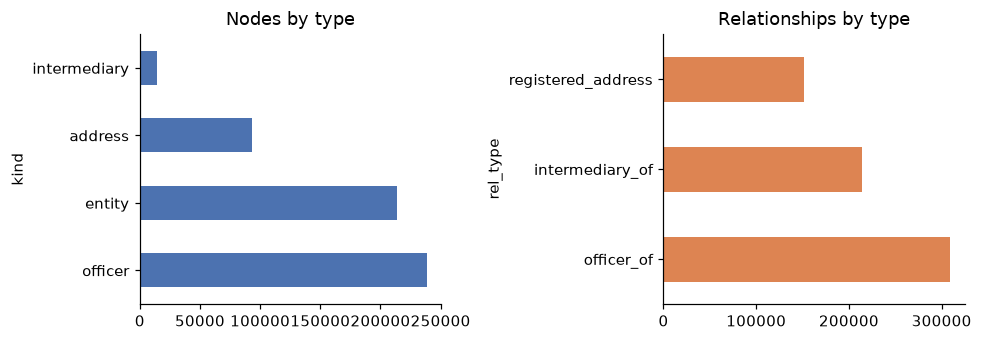

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
nodes.kind.value_counts().plot.barh(ax=ax[0], color="#4C72B0"); ax[0].set_title("Nodes by type")
rels.rel_type.value_counts().plot.barh(ax=ax[1], color="#DD8452"); ax[1].set_title("Relationships by type")
plt.tight_layout(); plt.savefig(FIG + "01_node_rel_types.png"); plt.show()

**Reading:** `registered_address` links are mostly officer -> address, so addresses add little to the entity graph.

In [4]:
d = edges_entity_connector(nodes, rels)
print("entity-connector links by connector type:"); print(d.groupby("ckind").size().to_string())

entity-connector links by connector type:
ckind
address           5310
intermediary    213634
officer         292743


## 3. Bipartite graph
Entities on one side, officers / intermediaries / addresses on the other. Undirected, simple.

In [5]:
B, P = pickle.load(open(PROC / "graphs.pkl", "rb"))  # built by src/run_stats.py
sB = stats(B, "bipartite"); print(json.dumps(sB, indent=1))

{
 "graph": "bipartite",
 "nodes": 468623,
 "edges": 511687,
 "type": "undirected simple",
 "density": 4.660023490239037e-06,
 "mean_degree": 2.183789528042798,
 "max_degree": 7016,
 "isolated": 0,
 "components": 12218,
 "largest_component": 310904,
 "largest_share": 0.6634416151149218,
 "top5_components": [
  310904,
  3642,
  2995,
  1468,
  1229
 ],
 "singleton_components": 0
}


## 4. Entity projection
Two entities are linked if they share a connector. Weight = number of shared connectors. Hubs are capped, otherwise a connector with `d` entities adds `d(d-1)/2` edges.

In [6]:
print("cap on connector degree:", CAP)
sP = stats(P, "projection"); print(json.dumps(sP, indent=1))
w = np.array([x for *_, x in P.edges(data="weight")])
print("edge weight: mean %.2f, max %d, share of weight-1 edges %.1f%%" % (w.mean(), w.max(), 100*(w==1).mean()))

cap on connector degree: {'officer': 500, 'intermediary': 50, 'address': 50}


{
 "graph": "projection",
 "nodes": 213634,
 "edges": 1238967,
 "type": "undirected simple, weighted",
 "density": 5.4293898082278016e-05,
 "mean_degree": 11.5989683290113,
 "max_degree": 720,
 "isolated": 129607,
 "components": 139643,
 "largest_component": 26643,
 "largest_share": 0.1247132947002818,
 "top5_components": [
  26643,
  132,
  126,
  121,
  115
 ],
 "singleton_components": 129607
}


edge weight: mean 1.17, max 73, share of weight-1 edges 83.8%


## 5. Summary table

In [7]:
tab = pd.DataFrame([sB, sP]).set_index("graph")[["nodes","edges","density","mean_degree","max_degree","components","largest_component","largest_share","isolated"]]
tab.T

graph,bipartite,projection
nodes,468623.000000,2.136340e+05
edges,511687.000000,1.238967e+06
density,0.000005,5.429390e-05
mean_degree,2.183790,1.159897e+01
max_degree,7016.000000,7.200000e+02
components,12218.000000,1.396430e+05
largest_component,310904.000000,2.664300e+04
largest_share,0.663442,1.247133e-01
isolated,0.000000,1.296070e+05


## 6. Degree distributions (log-log)

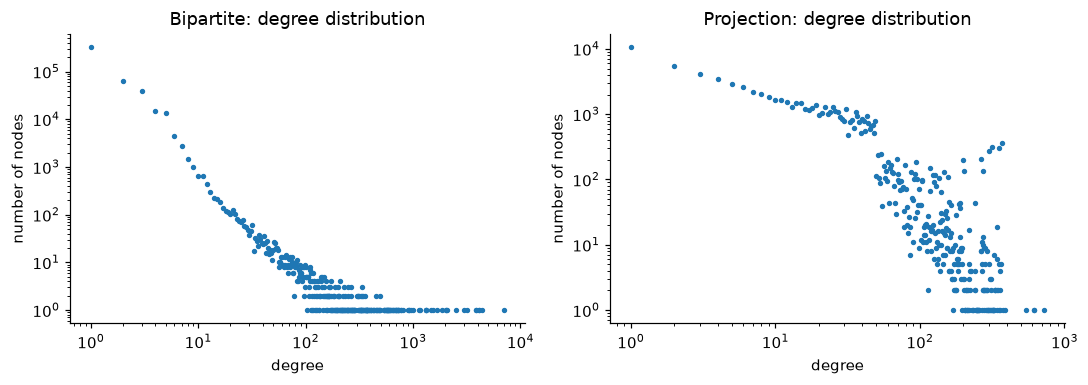

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, (G, t) in zip(ax, [(B, "Bipartite"), (P, "Projection")]):
    deg = np.array([x for _, x in G.degree()]); v, c = np.unique(deg[deg > 0], return_counts=True)
    a.loglog(v, c, ".", ms=5); a.set_title(t + ": degree distribution"); a.set_xlabel("degree"); a.set_ylabel("number of nodes")
plt.tight_layout(); plt.savefig(FIG + "01_degree_distributions.png"); plt.show()

## 7. Component sizes

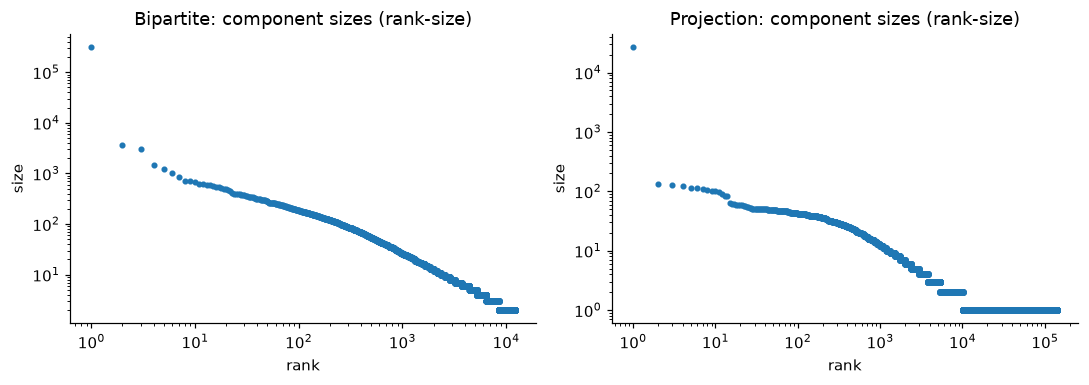

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, (G, t) in zip(ax, [(B, "Bipartite"), (P, "Projection")]):
    s = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    a.loglog(range(1, len(s)+1), s, "."); a.set_title(t + ": component sizes (rank-size)"); a.set_xlabel("rank"); a.set_ylabel("size")
plt.tight_layout(); plt.savefig(FIG + "01_component_sizes.png"); plt.show()

## 8. Conclusions and choices to justify in the report

- Heavy-tailed degrees: a few intermediaries and nominee officers act as hubs.
- The bipartite graph has one giant component (about 66 % of nodes) plus 12k small ones.
- The projection is fragmented: most entities are isolated because their connectors are shared by nobody, or exceed the cap.
- **Choices to defend:** Panama Papers only, undirected simple graph, caps (officers 500, intermediaries 50, addresses 50), centralities on the bipartite graph vs communities on the projection.
- **To test:** sensitivity of the intermediary cap (50, 100, 500).